In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
INVESTED = 170_726
FUND_SHARES = 727710 / 1940.094

In [3]:
name_map = {
    "avanza_global": "avanza_global",
    "avanza_zero": "avanza_zero",
    "cliens_smabolag_a": "cliens",
    "spiltan_aktiefond_investmentbolag": "spiltan",
    "swedbank_robur_tech_a": "swedbank",
    "nordea_alfa": "nordea",
    "coeli_frontiers_mkt": "coeli",
    "ct_lux_global_tech": "ct_lux",
    "dnb_teknologi_s": "dnb",
    "finserve": "finserve",
    "jpm_us_tech": "jpm_tech",
    "bgf_tech_a2": "bgf",
}

In [ ]:
frames = []
for file in Path(".").glob("data/*.csv"):
    if file.stem not in name_map.keys():
        continue
    frame = pd.read_csv(file)
    frame = frame[["Datum", "Senaste"]]
    frame = frame.rename(columns={"Datum": "date", "Senaste": "nav"})
    frame["date"] = pd.to_datetime(frame["date"])
    frame["nav"] = frame["nav"].str.replace(".", "").str.replace(",", ".").astype(float)
    frame = frame.sort_values("date")
    frame["name"] = name_map[file.stem]
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
names = df["name"].unique()
df = df.pivot_table(index="date", columns="name", values="nav", aggfunc="first")
df

,date,nav,name
0,2022-03-14,144.57,avanza_global
1,2022-03-15,147.20,avanza_global
2,2022-03-16,148.52,avanza_global
3,2022-03-17,149.77,avanza_global
4,2022-03-18,151.52,avanza_global
...,...,...,...
25857,2026-03-06,1327.73,swedbank
25858,2026-03-09,1346.16,swedbank
25859,2026-03-10,1340.87,swedbank
25860,2026-03-11,1365.47,swedbank


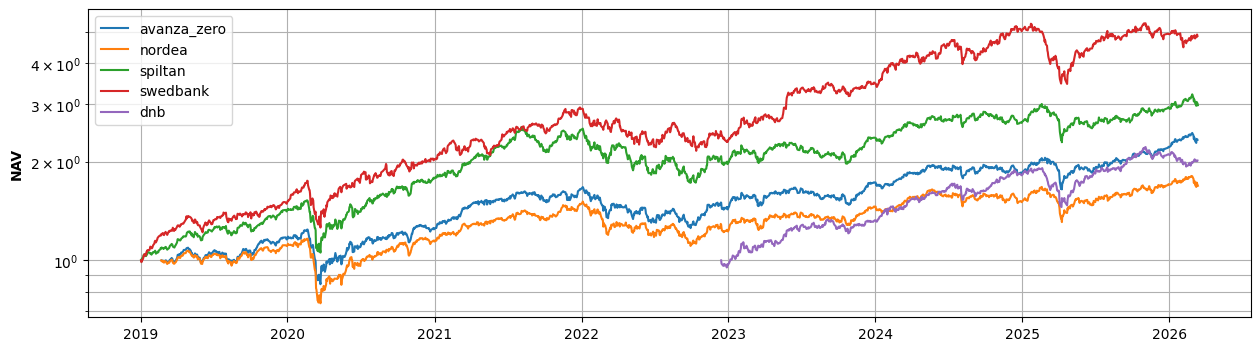

In [34]:
fig, ax = plt.subplots(figsize=(15, 4))
for name, s in df.query("date >= '2019-01-01'")[["avanza_zero", "nordea", "spiltan", "swedbank", "dnb"]].items():
    temp = s.dropna()
    temp = temp.div(temp.values[0])
    ax.semilogy(temp.index, temp.values, label=name, zorder=3)
ax.grid(zorder=1, which="both")
ax.legend()
ax.set_ylabel("NAV", fontweight="bold")
plt.show()

# Simulation

1. Sell Nordea.
    - calculate tax.
2. Invest remaining in another fund the same day.
3. Simulate ISK value forward
    - Deduct tax
4. Compare 

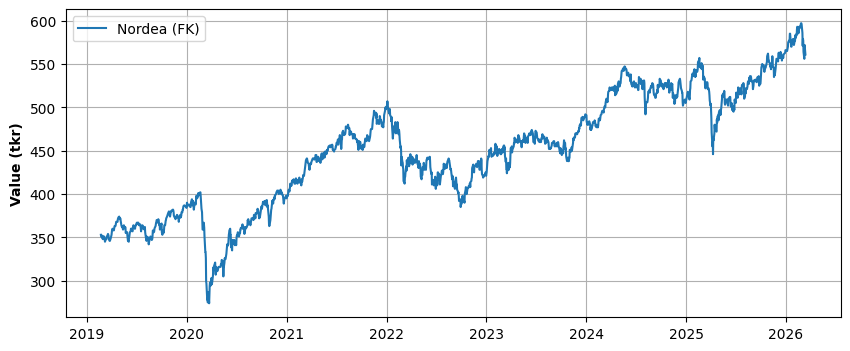

In [99]:
value_bt = df["nordea"].dropna().mul(FUND_SHARES)
tax = value_bt.sub(INVESTED).mul(0.3)
value_at = value_bt - tax

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(value_at.index, value_at.div(1e3).round().values, label="Nordea (FK)", zorder=3)
ax.grid(zorder=3, which="both")
ax.legend()
ax.set_ylabel("Value (tkr)", fontweight="bold")
plt.show()

In [174]:
def simulate(name: str, date: str, state_rate: float = 0.0196):
    """Simulate how a re-investment from Nordea Alfa to <name> at date <date> would
    progress. Tax is deducted from the ISK on the first trading day of each year.
    """
    df_pair = (
        df[["nordea", name]]
        .dropna()
        .assign(nordea_bt=lambda x: x["nordea"].mul(FUND_SHARES))
        .assign(profit=lambda x: x["nordea_bt"].sub(INVESTED))
        .assign(nordea_at=lambda x: x["nordea_bt"] - 0.3 * x["profit"])
    )

    dt = pd.to_datetime(date)
    df_filtered = df_pair.query("date >= @dt")[["nordea_bt", "nordea_at", name]]
    if df_filtered.empty:
        raise ValueError(f"Date {dt.date()} is not in the data")

    _, reinvested_sek, nav_new_fund = df_filtered.iloc[0]
    new_fund_shares = reinvested_sek / nav_new_fund
    df_filtered = df_filtered.assign(isk_without_tax=lambda x: x[name] * new_fund_shares)

    is_first_trading_day = df_filtered.index.year.diff() > 0
    tax = 0.3 * (0.01 + state_rate) * is_first_trading_day * df_filtered["isk_without_tax"]
    df_filtered["isk_value"] = df_filtered["isk_without_tax"] - tax.cumsum()
    out = pd.concat([df_pair, df_filtered[["isk_value"]]], axis=1)
    return out

In [175]:
temp = simulate(name="swedbank", date="2020-01-01")
temp

name,nordea,swedbank,nordea_bt,profit,nordea_at,isk_value
date,,,,,,
2019-02-21,1147.836,332.45,430541.888981,259815.888981,352597.122286,NaN
2019-02-22,1142.612,335.40,428582.418440,257856.418440,351225.492908,NaN
2019-02-25,1136.523,337.98,426298.494985,255572.494985,349626.746490,NaN
2019-02-26,1144.591,337.55,429324.721694,258598.721694,351745.105186,NaN
2019-02-27,1139.260,333.80,427325.116515,256599.116515,350345.381560,NaN
...,...,...,...,...,...,...
2026-03-06,1954.870,1327.73,733252.330918,562526.330918,564494.431643,1.172314e+06
2026-03-09,1923.974,1346.16,721663.548024,550937.548024,556382.283617,1.189242e+06
2026-03-10,1985.024,1340.87,744562.796978,573836.796978,572411.757885,1.184383e+06


In [194]:
df

name,avanza_global,avanza_zero,bgf,cliens,coeli,ct_lux,dnb,finserve,jpm_tech,nordea,spiltan,swedbank
date,,,,,,,,,,,,
2007-02-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.01,NaN,NaN,NaN
2007-02-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.05,NaN,NaN,NaN
2007-02-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.10,NaN,NaN,NaN
2007-02-22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.23,NaN,NaN,NaN
2007-02-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.13,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-09,223.10,505.88,106.96,2995.46,292.07,193.773,203.523,336.08,121.93,1923.974,885.36,1346.16
2026-03-10,222.51,520.46,111.68,3052.98,298.70,194.219,202.800,340.07,125.87,1985.024,910.14,1340.87
2026-03-11,223.96,516.44,111.80,3035.83,303.02,194.943,204.036,339.73,126.03,1968.206,899.19,1365.47


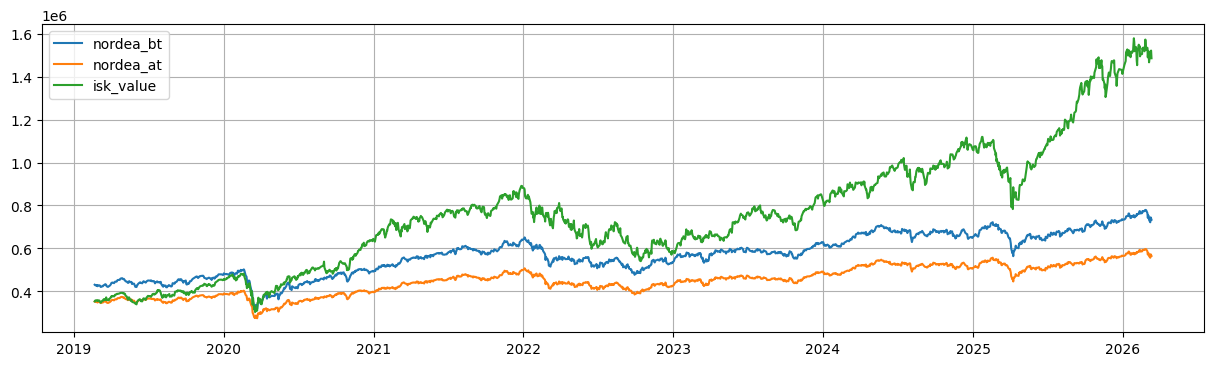

In [219]:
temp = simulate(name="ct_lux", date="2017-09-01")


fig, ax = plt.subplots(figsize=(15, 4))
for col in ["nordea_bt", "nordea_at", "isk_value"]:
    ax.plot(temp.index, temp[col], label=col, zorder=3)
ax.grid(zorder=1)
ax.legend()
plt.show()

In [190]:
days_to_recover = (
    temp.dropna()
    .assign(cmp=lambda x: x["isk_value"].ge(x["nordea_bt"]))
    .assign(days=lambda x: (x.index - x.index[0]).days)
    .query("cmp")
    .loc[:, "days"].min().item()
)
days_to_recover

404

In [229]:
c = 777084 - 0.3 * 595510 + 637000
for i in range(30):
    v = c * (1 + 0.025/100) ** (i * 250)
    print(i, 36 + i, round(v/1000))

0 36 1235
1 37 1315
2 38 1400
3 39 1490
4 40 1586
5 41 1689
6 42 1797
7 43 1913
8 44 2037
9 45 2168
10 46 2308
11 47 2457
12 48 2615
13 49 2784
14 50 2963
15 51 3154
16 52 3358
17 53 3574
18 54 3805
19 55 4050
20 56 4311
21 57 4589
22 58 4885
23 59 5200
24 60 5536
25 61 5893
26 62 6273
27 63 6677
28 64 7108
29 65 7566


In [225]:
0.98**(1/250)

0.999919192435837